# Feature Engineering

In [78]:
import pandas as pd
import numpy as np

df = pd.read_csv('/Users/david/Desktop/ml-ufc/data/ufc-master.csv')

fighter_features = [
    "age",
    "Height_cms",
    "Reach_cms",
    "wins",
    "losses",
    "current_win_streak",
    "current_lose_streak",
    "total_rounds_fought",
    "total_title_bouts",
    "avg_SIG_STR_pct",
    "avg_TD_landed",
    "avg_TD_pct",
    "avg_SUB_ATT",
    "win_by_KO/TKO",
    "win_by_Submission",
    "Stance"
]

features = (['R_' + feature for feature in fighter_features] + ['B_' + feature for feature in fighter_features]
            + ["weight_class", "title_bout", "no_of_rounds"])

In [79]:
def create_features(df):
    df = df.copy()

    df["age_diff"] = df["R_age"] - df["B_age"]

    df["R_Reach_cms"] = df["R_Reach_cms"].replace(0, np.nan)
    df["B_Reach_cms"] = df["B_Reach_cms"].replace(0, np.nan)

    df["reach_diff"] = (
        df["R_Reach_cms"] - df["B_Reach_cms"]
    )

    df["height_diff"] = (
        df["R_Height_cms"] - df["B_Height_cms"]
    )

    df["win_streak_diff"] = (
        df["R_current_win_streak"]
        - df["B_current_win_streak"]
    )

    df['lose_streak_diff'] = (
        df['R_current_lose_streak']
        - df['B_current_lose_streak']
    )

    df['wins_diff'] = (
        df['R_wins'] - df['B_wins']
    )

    df['losses_diff'] = (
        df['R_losses'] - df['B_losses']
    )

    r_total = df["R_wins"] + df["R_losses"] + df["R_draw"]
    b_total = df["B_wins"] + df["B_losses"] + df["B_draw"]

    df['R_is_debutant'] = (r_total == 0).astype(int)
    df['B_is_debutant'] = (b_total == 0).astype(int)

    df["experience_diff"] = r_total - b_total

    r_winrate = (df["R_wins"] / r_total).where(r_total > 0)
    b_winrate = (df["B_wins"] / b_total).where(b_total > 0)

    df["win_rate_diff"] = r_winrate - b_winrate


    return df

In [80]:
df_clean = df[df['Winner'].isin(['Red','Blue'])].copy() # skip draw, no contest
df_clean['date'] = pd.to_datetime(df_clean['date']) #make date from string to date
df_clean = df_clean.sort_values("date") #sort by date

split_idx = int(len(df_clean) * 0.8) #80% of old fight, and 20% for final test

train_df = df_clean.iloc[:split_idx].copy()
test_df = df_clean.iloc[split_idx:].copy()


In [81]:
train_df = create_features(train_df)
test_df = create_features(test_df)


In [82]:
new_features = [
    "age_diff",
    "reach_diff",
    "height_diff",
    "win_streak_diff",
    "lose_streak_diff",
    "wins_diff",
    "losses_diff",
    "experience_diff",
    "win_rate_diff",
    'R_is_debutant',
    'B_is_debutant'
]

train_df[new_features].describe().T

,count,mean,std,min,25%,50%,75%,max
age_diff,5735.0,0.569834,5.162882,-16.00,-3.000000,1.0,4.000000,17.00
reach_diff,5734.0,0.171179,8.308397,-30.48,-5.080000,0.0,5.080000,33.02
height_diff,5735.0,-0.040105,6.382188,-30.48,-5.080000,0.0,5.080000,33.02
win_streak_diff,5735.0,0.153618,1.807131,-10.00,0.000000,0.0,1.000000,16.00
lose_streak_diff,5735.0,0.126417,1.006029,-5.00,0.000000,0.0,1.000000,6.00
wins_diff,5735.0,1.472363,4.111995,-23.00,0.000000,1.0,3.000000,28.00
losses_diff,5735.0,0.711247,2.947743,-14.00,-1.000000,0.0,2.000000,18.00
experience_diff,5735.0,2.190061,6.621630,-27.00,-1.000000,1.0,5.000000,43.00
win_rate_diff,4517.0,0.045243,0.314247,-1.00,-0.141026,0.0,0.217391,1.00
R_is_debutant,5735.0,0.077245,0.267003,0.00,0.000000,0.0,0.000000,1.00


In [83]:
missing_values = train_df[new_features].isna().sum()

missing_percentage = (
    train_df[new_features].isna().mean() * 100
)

print("Missing values:")
print(missing_values)

print("\nMissing percentage:")
print(missing_percentage)

Missing values:
age_diff               0
reach_diff             1
height_diff            0
win_streak_diff        0
lose_streak_diff       0
wins_diff              0
losses_diff            0
experience_diff        0
win_rate_diff       1218
R_is_debutant          0
B_is_debutant          0
dtype: int64

Missing percentage:
age_diff             0.000000
reach_diff           0.017437
height_diff          0.000000
win_streak_diff      0.000000
lose_streak_diff     0.000000
wins_diff            0.000000
losses_diff          0.000000
experience_diff      0.000000
win_rate_diff       21.238012
R_is_debutant        0.000000
B_is_debutant        0.000000
dtype: float64


In [84]:
import numpy as np

inf_count = np.isinf(
    train_df[new_features].to_numpy(dtype=float)
).sum()

print("Infinite values:", inf_count)

Infinite values: 0


In [85]:
idx = train_df['reach_diff'].idxmax()

train_df.loc[idx,
             [
    "R_fighter",
    "B_fighter",
    "R_Reach_cms",
    "B_Reach_cms",
    "reach_diff"
             ]]

R_fighter         Miguel Torres
B_fighter      Antonio Banuelos
R_Reach_cms              193.04
B_Reach_cms              160.02
reach_diff                33.02
Name: 6940, dtype: object

In [86]:
print((train_df["R_Reach_cms"] == 0).sum())
print((train_df["B_Reach_cms"] == 0).sum())

0
0


### Data Quality — Invalid Reach Values

#### Problem

During feature validation, an extreme
reach difference of 187.96 cm was detected.

Fight:
- Red: Giga Chikadze
- Blue: Irwin Rivera

Original values:
- R_Reach_cms: 187.96
- B_Reach_cms: 0.0

#### Investigation

- Zero reach values in Red: 0
- Zero reach values in Blue: 1

A reach value of zero is physically impossible.

This suggests a missing value encoded as zero.

#### Solution

Replace invalid zero reach measurements
with NaN before feature engineering.

Missing values will be handled using
SimpleImputer fitted on training data.


In [87]:
print(train_df["reach_diff"].isna().sum())
print(train_df["reach_diff"].describe())

1
count    5734.000000
mean        0.171179
std         8.308397
min       -30.480000
25%        -5.080000
50%         0.000000
75%         5.080000
max        33.020000
Name: reach_diff, dtype: float64


In [88]:
r_total = (
    train_df["R_wins"] +
    train_df["R_losses"] +
    train_df["R_draw"]
)

b_total = (
    train_df["B_wins"] +
    train_df["B_losses"] +
    train_df["B_draw"]
)

print("Red debutants:", (r_total == 0).sum())
print("Blue debutants:", (b_total == 0).sum())

print(
    "Fights with at least one debutant:",
    ((r_total == 0) | (b_total == 0)).sum()
)

Red debutants: 443
Blue debutants: 1052
Fights with at least one debutant: 1218


In [89]:
debutant_mask = (r_total == 0) | (b_total == 0)
missing_mask = train_df["win_rate_diff"].isna()

print((debutant_mask == missing_mask).all())

True


In [90]:
quality_report = pd.DataFrame({
    "dtype": train_df[features].dtypes,
    "missing_count": train_df[features].isna().sum(),
    "missing_pct": train_df[features].isna().mean() * 100
})

quality_report.sort_values(
    "missing_pct",
    ascending=False
)

,dtype,missing_count,missing_pct
B_avg_TD_pct,float64,842,14.681779
B_avg_TD_landed,float64,833,14.524847
B_avg_SUB_ATT,float64,832,14.507411
B_avg_SIG_STR_pct,float64,765,13.339146
R_avg_TD_pct,float64,367,6.399303
R_avg_TD_landed,float64,357,6.224935
R_avg_SIG_STR_pct,float64,357,6.224935
R_avg_SUB_ATT,float64,357,6.224935
B_Stance,str,2,0.034874
B_Reach_cms,float64,1,0.017437


In [94]:
all_features = new_features + features

X_train = (train_df[all_features])
y_train = (train_df['Winner'] == 'Red').astype(int)

X_test = (test_df[all_features])
y_test = (test_df['Winner'] == 'Red').astype(int)

In [95]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("Features:", len(all_features))

X_train: (5735, 46)
y_train: (5735,)
X_test: (1434, 46)
y_test: (1434,)
Features: 46


In [96]:
print("Debutant features:",
      "R_is_debutant" in all_features,
      "B_is_debutant" in all_features)

print("Duplicates:",
      len(all_features) - len(set(all_features)))

print("Total:", len(all_features))

Debutant features: True True
Duplicates: 0
Total: 46


# Next step

In [97]:
X_train.isna().sum()

age_diff                    0
reach_diff                  1
height_diff                 0
win_streak_diff             0
lose_streak_diff            0
wins_diff                   0
losses_diff                 0
experience_diff             0
win_rate_diff            1218
R_is_debutant               0
B_is_debutant               0
R_age                       0
R_Height_cms                0
R_Reach_cms                 0
R_wins                      0
R_losses                    0
R_current_win_streak        0
R_current_lose_streak       0
R_total_rounds_fought       0
R_total_title_bouts         0
R_avg_SIG_STR_pct         357
R_avg_TD_landed           357
R_avg_TD_pct              367
R_avg_SUB_ATT             357
R_win_by_KO/TKO             0
R_win_by_Submission         0
R_Stance                    0
B_age                       0
B_Height_cms                0
B_Reach_cms                 1
B_wins                      0
B_losses                    0
B_current_win_streak        0
B_current_

In [102]:
X_train['title_bout'] = X_train['title_bout'].astype(int)
X_test['title_bout'] = X_test['title_bout'].astype(int)

In [103]:
cat_val = X_train.select_dtypes(include=['object','string'])
num_val = X_train.select_dtypes(exclude=['object', 'string'])

print(num_val.columns)
print(cat_val.columns)


Index(['age_diff', 'reach_diff', 'height_diff', 'win_streak_diff',
       'lose_streak_diff', 'wins_diff', 'losses_diff', 'experience_diff',
       'win_rate_diff', 'R_is_debutant', 'B_is_debutant', 'R_age',
       'R_Height_cms', 'R_Reach_cms', 'R_wins', 'R_losses',
       'R_current_win_streak', 'R_current_lose_streak',
       'R_total_rounds_fought', 'R_total_title_bouts', 'R_avg_SIG_STR_pct',
       'R_avg_TD_landed', 'R_avg_TD_pct', 'R_avg_SUB_ATT', 'R_win_by_KO/TKO',
       'R_win_by_Submission', 'B_age', 'B_Height_cms', 'B_Reach_cms', 'B_wins',
       'B_losses', 'B_current_win_streak', 'B_current_lose_streak',
       'B_total_rounds_fought', 'B_total_title_bouts', 'B_avg_SIG_STR_pct',
       'B_avg_TD_landed', 'B_avg_TD_pct', 'B_avg_SUB_ATT', 'B_win_by_KO/TKO',
       'B_win_by_Submission', 'title_bout', 'no_of_rounds'],
      dtype='str')
Index(['R_Stance', 'B_Stance', 'weight_class'], dtype='str')


In [108]:
print("Numerical:", num_val.shape[1])
print("Categorical:", cat_val.shape[1])
print("Total:", num_val.shape[1] + cat_val.shape[1])

Numerical: 43
Categorical: 3
Total: 46


In [109]:
numerical_features = num_val.columns.tolist()
categorical_features = cat_val.columns.tolist()

print(len(numerical_features))
print(len(categorical_features))

43
3


In [115]:
some_table = num_val.describe().T
some_table[['mean', 'count', '50%', 'std']]

,mean,count,50%,std
age_diff,0.569834,5735.0,1.0000,5.162882
reach_diff,0.171179,5734.0,0.0000,8.308397
height_diff,-0.040105,5735.0,0.0000,6.382188
win_streak_diff,0.153618,5735.0,0.0000,1.807131
lose_streak_diff,0.126417,5735.0,0.0000,1.006029
wins_diff,1.472363,5735.0,1.0000,4.111995
losses_diff,0.711247,5735.0,0.0000,2.947743
experience_diff,2.190061,5735.0,1.0000,6.621630
win_rate_diff,0.045243,4517.0,0.0000,0.314247
R_is_debutant,0.077245,5735.0,0.0000,0.267003


In [121]:
nulls_num = num_val.isnull().sum()
nulls_num_v = nulls_num[nulls_num > 0]
nulls_num_columns = nulls_num_v.index.tolist()


num_val[nulls_num_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
reach_diff,5734.0,0.171179,8.308397,-30.48,-5.080000,0.0000,5.080000,33.02
win_rate_diff,4517.0,0.045243,0.314247,-1.00,-0.141026,0.0000,0.217391,1.00
R_avg_SIG_STR_pct,5378.0,0.457303,0.101560,0.00,0.400000,0.4560,0.511750,1.00
R_avg_TD_landed,5378.0,1.371650,1.288094,0.00,0.438125,1.0000,2.000000,12.50
R_avg_TD_pct,5368.0,0.336868,0.222735,0.00,0.193000,0.3320,0.468000,1.00
R_avg_SUB_ATT,5378.0,0.524126,0.656723,0.00,0.000000,0.3333,0.800000,8.30
B_Reach_cms,5734.0,182.340497,10.812781,147.32,175.260000,182.8800,190.500000,213.36
B_avg_SIG_STR_pct,4970.0,0.449376,0.114788,0.00,0.393000,0.4570,0.510000,1.00
B_avg_TD_landed,4902.0,1.292751,1.348954,0.00,0.285700,1.0000,1.909775,10.86
B_avg_TD_pct,4893.0,0.319759,0.241713,0.00,0.133000,0.3300,0.470000,1.00


<Axes: >

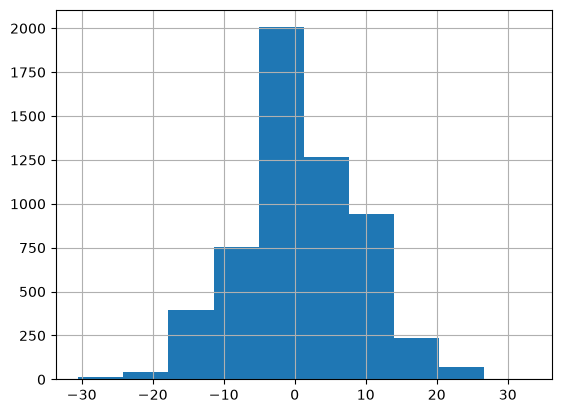

In [ ]:
num_val['reach_diff'].hist() #mean can be good

<Axes: >

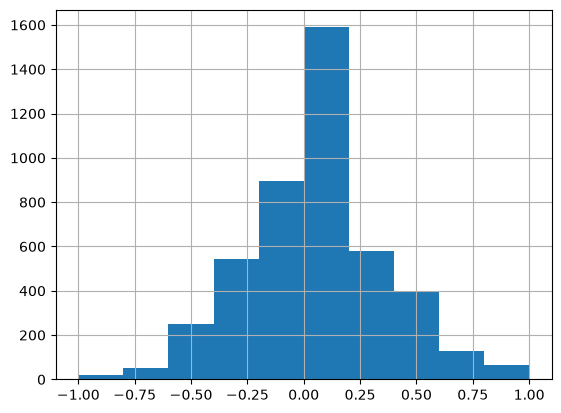

In [ ]:
num_val['win_rate_diff'].hist() # mean

<Axes: >

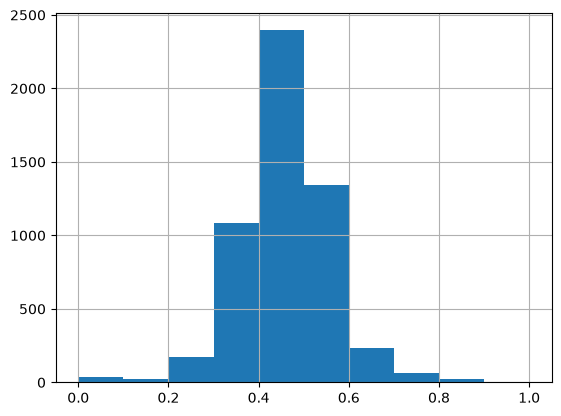

In [ ]:
num_val['R_avg_SIG_STR_pct'].hist()# mean or median, they barely same values

<Axes: >

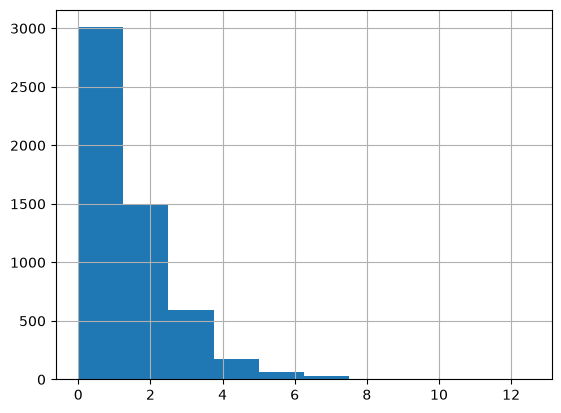

In [ ]:
num_val['R_avg_TD_landed'].hist() # right skewed median

<Axes: >

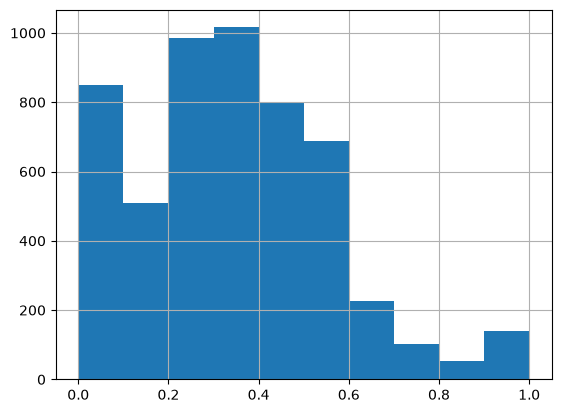

In [ ]:
num_val['R_avg_TD_pct'].hist()# median

<Axes: >

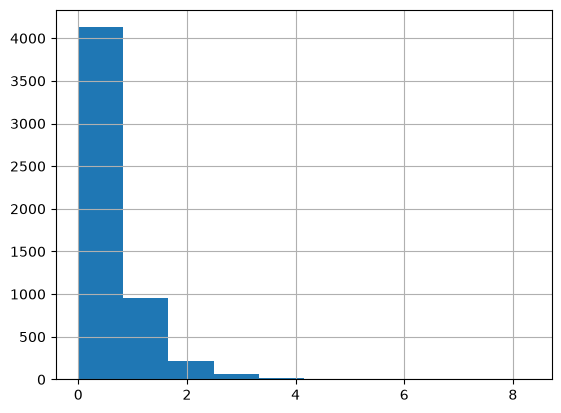

In [ ]:
num_val['R_avg_SUB_ATT'].hist()#median

<Axes: >

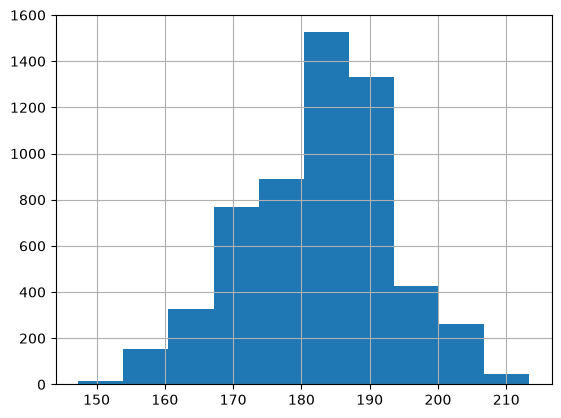

In [ ]:
num_val['B_Reach_cms'].hist() #median or mean

<Axes: >

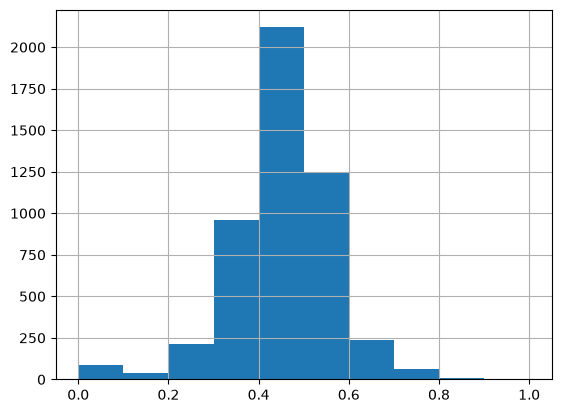

In [ ]:
num_val['B_avg_SIG_STR_pct'].hist() #mean or median

<Axes: >

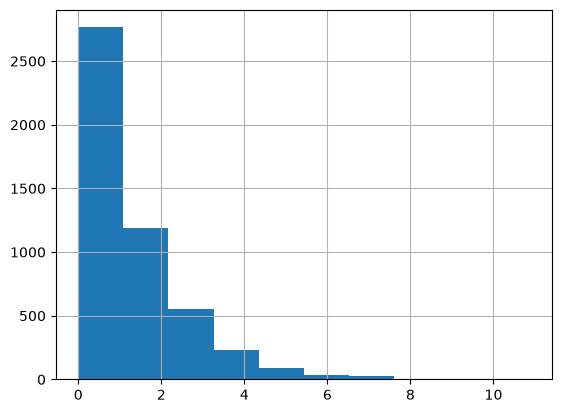

In [ ]:
num_val['B_avg_TD_landed'].hist() # median

<Axes: >

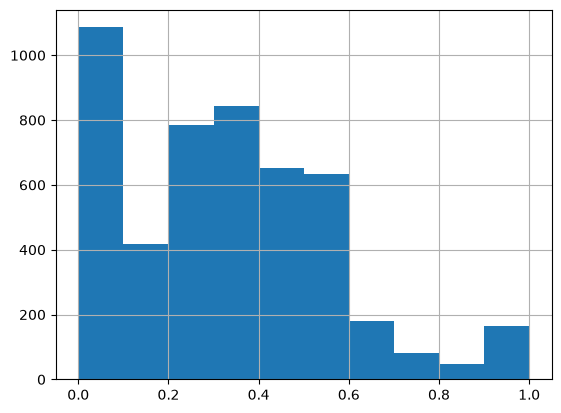

In [ ]:
num_val['B_avg_TD_pct'].hist() # median

<Axes: >

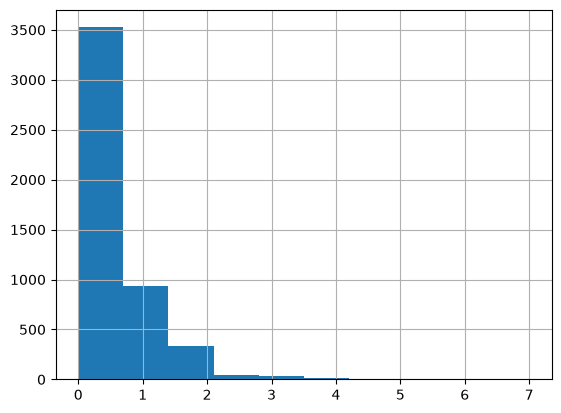

In [ ]:
num_val['B_avg_SUB_ATT'].hist() # median

In [136]:
nulls_cat = cat_val.isnull().sum()
nulls_cat


R_Stance        0
B_Stance        2
weight_class    0
dtype: int64

### Imputation Strategy — Final Decision

#### Numerical Features

Mean imputation:
- reach_diff
- B_Reach_cms
- R_avg_SIG_STR_pct
- B_avg_SIG_STR_pct

Median imputation:
- win_rate_diff
- R_avg_TD_landed / B_avg_TD_landed
- R_avg_TD_pct / B_avg_TD_pct
- R_avg_SUB_ATT / B_avg_SUB_ATT

#### Categorical Features

Most-frequent imputation for missing stances.

#### Reasoning

- Mean is suitable for approximately symmetric
  distributions without severe outliers.
- Median is more robust to skewness and outliers.
- Missing UFC statistics do not necessarily mean zero.
- Debutant indicators preserve some information
  about missing historical performance.

#### Important

All imputation statistics must be learned
from training data inside the ML Pipeline.

The chosen strategies are initial hypotheses
and may be compared during validation.

In [137]:
mean_features = ['reach_diff', 'B_Reach_cms', 'R_avg_SIG_STR_pct', 'B_avg_SIG_STR_pct']
median_features = [feature for feature in numerical_features if feature not in mean_features]
mode_feature = cat_val.columns.tolist()


print(len(mean_features))
print(len(median_features))
print(len(categorical_features))


4
39
3


In [138]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


num_pipeline_mean = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('std_scaler', StandardScaler())
])

num_pipeline_median = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('std_scaler', StandardScaler())
])

cat_pipeline_mode = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('one_hot', OneHotEncoder(handle_unknown='ignore'))
])

full_pipeline = ColumnTransformer([
    ('num_mean', num_pipeline_mean, mean_features),
    ('num_median', num_pipeline_median, median_features),
    ('cat_mode', cat_pipeline_mode, mode_feature)
])

selected_features = mean_features + median_features + mode_feature

print("Duplicates:", len(selected_features) - len(set(selected_features)))
print("Missing:", set(X_train.columns) - set(selected_features))



Duplicates: 0
Missing: set()
